<div class="alert alert-info">
<h1>Logistics Regression</h1>
<h4>Homework to Environmental Statistics 3</h4>
<h4>Your Names in Here!</h4>
</div>

This weeks exercises will practice the content of the lecture and tutorials and *extend* them in different ways:
 
  * using fitted curve to read off x for a given y (useful e.g. in LD50 value computation);
  * 3D-plotting with added data points.

# 1. Exercise 1 (10 points): Effect of temperature on sex in turtles
It is not uncommon, in plants, fish, crustaceans and reptiles, that [sex-determination is through environmental conditions](https://en.wikipedia.org/wiki/Environmental_sex_determination) during egg development. In this data set (**faraway**'s `turtle`), the number of male and female turtles emerging from eggs incubated at different temperatures is counted.

  1. Plot the data in a meaningful way. (**2 points**)
  2. Analyse the data, i.e. what is the probability of an female to emerge from an egg, given the temperature? (**2 points**)
  3. Plot the data and the fitted GLM, with 95\% confidence interval. (**2 points**)
  4. Compute at which temperature there will be exactly a 50:50 chance that the egg will yield a female turtle? (**2 points**)
  5. Interpret findings, including the previous step. (**2 points**)

### 1.1    Load the data and look at the *summary* of it.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.mosaicplot import mosaic
import statsmodels.api as sm


turtle = pd.read_csv("X:/Mitarbeiter_innen/Ikedichi/ik1015/Ikedichi_Python/turtle.csv")
turtle.describe()

,temp,male,female
count,15.000000,15.000000,15.000000
mean,28.300000,6.066667,3.000000
std,0.941883,3.514595,2.976095
min,27.200000,0.000000,0.000000
25%,27.700000,4.500000,1.000000
50%,28.300000,7.000000,2.000000
75%,28.400000,7.500000,3.000000
max,29.900000,13.000000,9.000000


### 1.1 Plot

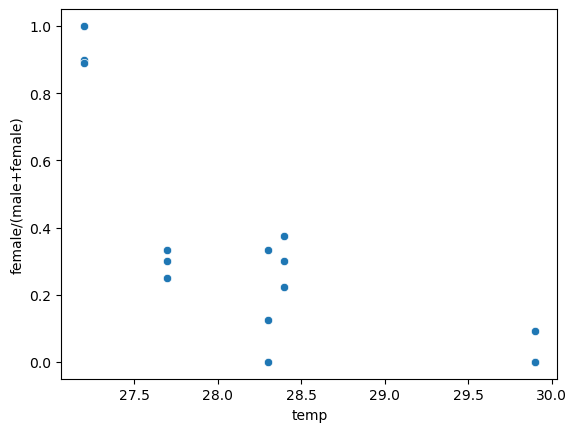

In [5]:
sns.scatterplot(x = turtle['temp'],
                y = turtle['female']/(turtle['male']+turtle['female']))
plt.ylabel('female/(male+female)')
plt.show()

### 1.2 Analyse

In [8]:
X = turtle['temp']
y = turtle[['female', 'male']]

# Add a constant term for the intercept
X = sm.add_constant(X)

# Fit logistic regression model
fm = sm.GLM(y, X, family=sm.families.Binomial()).fit()

# Print the summary of the model
print(fm.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:     ['female', 'male']   No. Observations:                   15
Model:                            GLM   Df Residuals:                       13
Model Family:                Binomial   Df Model:                            1
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -24.918
Date:                Thu, 12 Oct 2023   Deviance:                       24.942
Time:                        10:30:01   Pearson chi2:                     26.2
No. Iterations:                     6   Pseudo R-squ. (CS):             0.9633
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         61.3183     12.022      5.100      0.0

In [9]:
## OR

X = turtle['temp']
y = turtle['female'] / (turtle['female'] + turtle['male'])
weights = turtle['female'] + turtle['male']

# Add a constant term for the intercept
X = sm.add_constant(X)

# Fit logistic regression model
fm2 = sm.GLM(y, X, family=sm.families.Binomial(), freq_weights=weights).fit()


# Print the summary of the model
print(fm2.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                   15
Model:                            GLM   Df Residuals:                      134
Model Family:                Binomial   Df Model:                            1
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -45.918
Date:                Thu, 12 Oct 2023   Deviance:                       24.942
Time:                        10:33:25   Pearson chi2:                     26.2
No. Iterations:                     6   Pseudo R-squ. (CS):             0.9633
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         61.3183     12.022      5.100      0.0

In [14]:
## OR (like R-way)

turtle2 = turtle.copy()
turtle2['response'] = turtle2['female'] / (turtle2['female'] + turtle2['male'])
turtle2['weights'] = turtle['female'] + turtle['male']

# Define the formula
formula = "response ~ temp"

# Fit the GLM
fm3 = sm.GLM.from_formula(formula, family=sm.families.Binomial(),freq_weights=weights, data=turtle2).fit() 

# Print the summary
print(fm3.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:               response   No. Observations:                   15
Model:                            GLM   Df Residuals:                      134
Model Family:                Binomial   Df Model:                            1
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -45.918
Date:                Thu, 12 Oct 2023   Deviance:                       24.942
Time:                        10:44:02   Pearson chi2:                     26.2
No. Iterations:                     6   Pseudo R-squ. (CS):             0.9633
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     61.3183     12.022      5.100      0.0

### 1.3 Plot with regression line

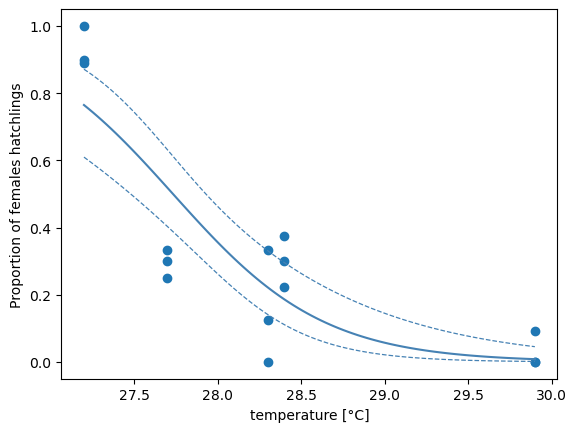

In [35]:
plt.scatter(turtle2['temp'], turtle2['response'])
plt.ylabel("Proportion of females hatchlings")
plt.xlabel("temperature [°C]")

newTemp = np.linspace(min(turtle['temp']), max(turtle['temp']), num=100)
newTemp_df = pd.DataFrame(list(newTemp), columns=["temp"])

preds = fm3.get_prediction(newTemp_df).summary_frame(alpha=0.05)

plt.plot(newTemp, preds['mean'], color='steelblue')
plt.plot(newTemp, preds['mean_ci_upper'], color='steelblue',linestyle='--',linewidth=0.9)
plt.plot(newTemp, preds['mean_ci_lower'], color='steelblue',linestyle='--',linewidth=0.9)
plt.show()


### 1.4 Temperature of P(female | temperature) = 0.5

*Alternatively, reformulate the GLM equation:*
$$\log(P(\text{female})) = \log(0.5) = 0 = 61.3 - 2.21t$$

$$ \Longleftrightarrow t = 61.3 / 2.21 =  27.74$$

*To get the standard error for this estimate, you have to use equations from [propagation of uncertainty](https://en.wikipedia.org/wiki/Propagation_of_uncertainty#Example_formulae), which takes us too far and is not part of the question.*

$$ f = A/B = \frac{61.3\pm12.02}{2.21 \pm 0.431}$$

We will need the covariance of the two estimates (intercept and temperature):

In [36]:
# Get the variance-covariance matrix
var_cov_matrix = fm.cov_params()

# Print the variance-covariance matrix
print(var_cov_matrix)

            const      temp
const  144.538239 -5.179042
temp    -5.179042  0.185637


$$\text{Then: } \sigma^2_f \approx  f^2 \left ( \frac{\sigma_A^2}{A^2} + \frac{\sigma_B^2}{B^2} - \frac{2\sigma_{AB}}{AB} \right )$$

$$ = 27.74^2(12.0224^2/61.32^2 + 0.4309^2/2.211^2 - 2\cdot(-5.179)/(61.32\cdot -2.211)) $$

$$ = 769.5\cdot (0.03844+0.03798- 0.07639) = 0.023085$$

$$ \Longrightarrow \sigma_f = \sqrt{0.023085} = 0.152.$$

This value is somewhat too high, largely because I rounded too early. (This is relevant, because the partial errors and the partial covariance almost exactly cancel, so that every digit counts.) But you get the gist, I hope.

## 1.5 Interpretation
The data suggest a strong temperature-dependence of sex determination, switching from largely females at temperatures below 27°C to almost exclusively male above 29°C (P < 0.0001). The proportion of females is 50% at a temperature of $27.7 \pm 0.11$°C.


# Exercise 2: Coronary heart disesase in San Francisco (12 points)

Coronary heart disease (CHD) is a common cause of death in the developed world. In this study, researchers wanted to find correlates of CHD across a range of study participants from around San Francisco. We will focus (medically inappropriately, but didactically importantly) on weight and cholesterol levels as "predictor" of CHD. Note that these are correlations, and hence in medicine they speak of "risk factors", not causal predictors.

  1. Plot CHD incidence as functions of weight and cholesterol levels, separately. (**2 points**)
  2. Analyse CHD incidence as function of weight, chostestrol and their interaction. Briefly say something about the model's quality and what the parameters suggest about the relationship between the two risk factors and CHD. (**3 points**)
  3. Plot the interactions, and the probability of CHD as response (3D-like). Add the observed data points as "+". Remove extremes for weight and cholesterol to "zoom" into the part of the plot that is well-supported by measurements. Re-plot and add data as "." (taking up less space). Choose a plot that shows a scale bar for colours. (**5 points**)
  4. Interpret the relationship between weight, cholesterol and probability of CHD, i.e. put the statistical interaction into words. (**2 points**)

In [85]:
wcg = pd.read_csv("X:/Mitarbeiter_innen/Ikedichi/ik1015/Ikedichi_Python/wcgs.csv")
wcgs = wcg.drop('year', axis=1)
wcgs.index = wcg['year']

wcgs.describe()

,age,height,weight,sdp,dbp,chol,cigs,timechd
count,3154.000000,3154.000000,3154.000000,3154.000000,3154.000000,3142.000000,3154.000000,3154.000000
mean,46.278694,69.777743,169.953710,128.632847,82.015536,226.372374,11.600507,2683.859226
std,5.524045,2.528693,21.095762,15.117731,9.726880,43.420426,14.517579,666.524135
min,39.000000,60.000000,78.000000,98.000000,58.000000,103.000000,0.000000,18.000000
25%,42.000000,68.000000,155.000000,120.000000,76.000000,197.250000,0.000000,2842.250000
50%,45.000000,70.000000,170.000000,126.000000,80.000000,223.000000,0.000000,2942.000000
75%,50.000000,72.000000,182.000000,136.000000,86.000000,253.000000,20.000000,3036.750000
max,59.000000,78.000000,320.000000,230.000000,150.000000,645.000000,99.000000,3430.000000


In [87]:
wcgs.head()

,age,height,weight,sdp,dbp,chol,behave,cigs,dibep,chd,typechd,timechd,arcus
year,,,,,,,,,,,,,
2001,49,73,150,110,76,225.0,A2,25,B,no,none,1664,absent
2002,42,70,160,154,84,177.0,A2,20,B,no,none,3071,present
2003,42,69,160,110,78,181.0,B3,0,A,no,none,3071,absent
2004,41,68,152,124,78,132.0,B4,20,A,no,none,3064,absent
2005,59,70,150,144,86,255.0,B3,20,A,yes,infdeath,1885,present


### 2.1 Plot

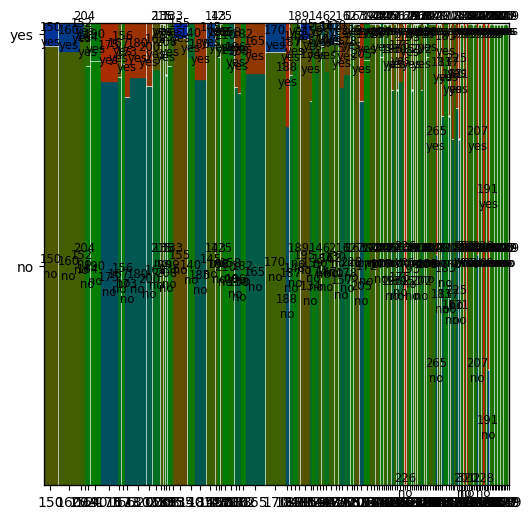

In [102]:
fig, ax = plt.subplots(figsize=(6, 6))
mosaic(wcgs, ['weight','chd'], ax=ax, statistic=lambda x: sum(x), labelizer=None)
plt.xticks(rotation=90)

plt.show()

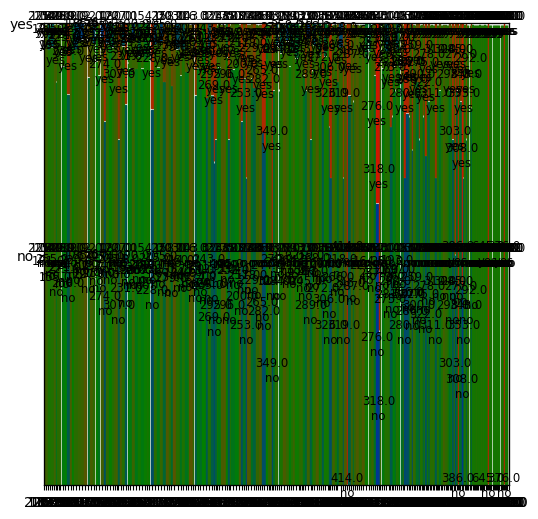

In [144]:
fig, ax = plt.subplots(figsize=(6, 6))
mosaic(wcgs, ['chol','chd'], ax=ax, statistic=lambda x: sum(x), labelizer=None)
plt.show()

Note that the majority of participants did not develop CHD.

### 2.2 Analyse

In [94]:
# Define the formula
formula = "chd ~ (weight + chol)**2"

# Fit the GLM
fm4 = sm.GLM.from_formula(formula, family=sm.families.Binomial(), data=wcgs).fit() 

# Print the summary
print(fm4.summary())

'''
Note that this code fits 'chd[no]' as 1 and chd[yes] as 0
'''

                    Generalized Linear Model Regression Results                    
Dep. Variable:     ['chd[no]', 'chd[yes]']   No. Observations:                 3142
Model:                                 GLM   Df Residuals:                     3138
Model Family:                     Binomial   Df Model:                            3
Link Function:                       Logit   Scale:                          1.0000
Method:                               IRLS   Log-Likelihood:                -842.35
Date:                     Thu, 12 Oct 2023   Deviance:                       1684.7
Time:                             12:56:18   Pearson chi2:                 3.03e+03
No. Iterations:                          6   Pseudo R-squ. (CS):            0.02963
Covariance Type:                 nonrobust                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------


In [95]:
# Recode to allow chd[yes] take the value of 1 so that the same results as in R is produced.

wcgs['chd_encoded'] = (wcgs['chd'] == 'yes').astype(int)  # 1 if 'yes', 0 if 'no'

# Define the formula
formula = "chd_encoded ~ (weight + chol)**2"

# Fit the GLM
fm5 = sm.GLM.from_formula(formula, family=sm.families.Binomial(), data=wcgs).fit()

# Print the summary
print(fm5.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:            chd_encoded   No. Observations:                 3142
Model:                            GLM   Df Residuals:                     3138
Model Family:                Binomial   Df Model:                            3
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -842.35
Date:                Thu, 12 Oct 2023   Deviance:                       1684.7
Time:                        13:09:32   Pearson chi2:                 3.03e+03
No. Iterations:                     6   Pseudo R-squ. (CS):            0.02963
Covariance Type:            nonrobust                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept     -13.2134      2.580     -5.121      

This model, despite its significant predictors, explains hardly any of the observed variation in the data. 

Both increasing weight and cholesterol levels are risk factors for CHD. The negative sign in the interaction indicates that having both is not additive, but sub-additive. That means, heavier people with high cholesterol levels have *lower* risk of CHD than would be predicted from the univariate effects added together.

### 2.3  Plot interaction
Note that the units given for cholesterol in the help cannot be correct. The [test value chart](https://en.wikipedia.org/wiki/Cholesterol#Testing) suggests that the units are mg/dl.

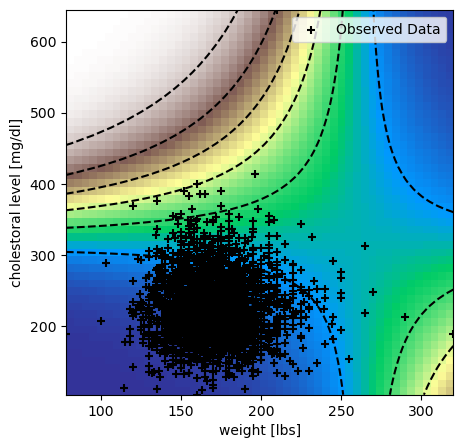

In [119]:
## As a Contour ##

newWeight = np.linspace(min(wcgs.weight), max(wcgs.weight), num=50)
newChol = np.linspace(min(wcgs.chol), max(wcgs.chol), num=50)

# Create a grid of new data points
x, y = np.meshgrid(newWeight, newChol)

# Predict using the model
z = fm5.predict(pd.DataFrame({"weight": x.flatten(), "chol": y.flatten()}))

# Reshape the predictions back to the grid shape
z = z.values.reshape(x.shape)

plt.figure(figsize=(5,5))

# Create the filled color representation
plt.imshow(z, extent=[min(newWeight), max(newWeight), min(newChol), max(newChol)], 
           origin='lower', cmap='terrain', aspect='auto')

# Add labels and title
plt.xlabel("weight [lbs]")
plt.ylabel("cholestoral level [mg/dl]")

# Add contour lines
plt.contour(newWeight, newChol, z, colors='black', linestyles='--')

# Add scattered points from 'wcgs'
plt.scatter(wcgs['weight'], wcgs['chol'], marker='+', color='black', label='Observed Data')

# Add legend
plt.legend()

plt.show()

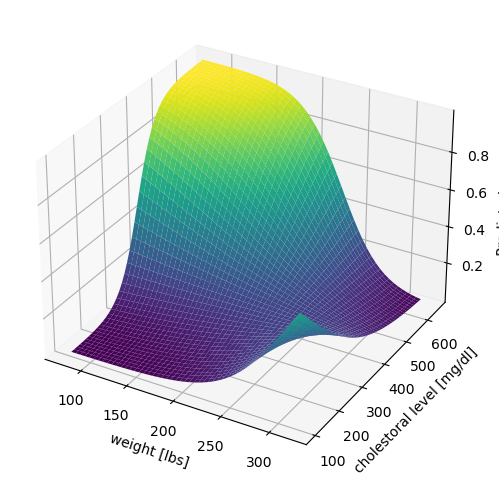

In [120]:
## Or as a 3D plotting

# Predict using the model
z = fm5.predict(pd.DataFrame({"weight": x.flatten(), "chol": y.flatten()}))

# Reshape the predictions back to the grid shape
z = z.values.reshape(x.shape)

# Create the 3D surface plot
fig = plt.figure(figsize=(6,8))
ax = fig.add_subplot(projection='3d')

# Plot the surface
ax.plot_surface(x, y, z, cmap='viridis')

# Set labels
ax.set_xlabel("weight [lbs]")
ax.set_ylabel("cholestoral level [mg/dl]")
ax.set_zlabel('Predicted Value')

plt.show()



Re-drawn to exclude the one extremely high value for chol, and the lowest and heighest for `weight`:

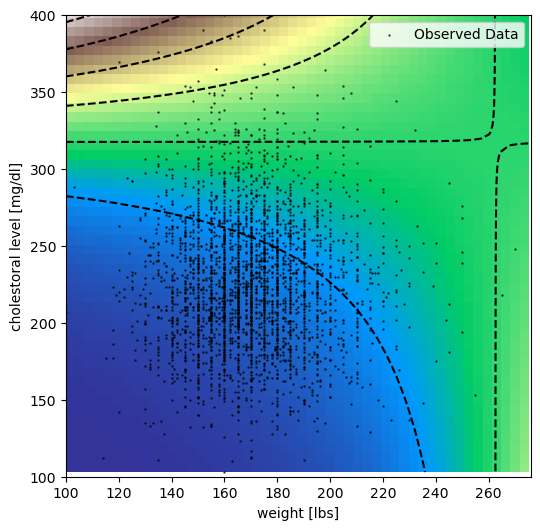

In [143]:
newWeight2 = np.linspace(100, 275, num=50)
newChol2 = np.linspace(min(wcgs.chol), 410, num=50)

# Create a grid of new data points
x, y = np.meshgrid(newWeight2, newChol2)

# Predict using the model
z = fm5.predict(pd.DataFrame({"weight": x.flatten(), "chol": y.flatten()}))

# Reshape the predictions back to the grid shape
z = z.values.reshape(x.shape)

plt.figure(figsize=(6,6))

# Create the filled color representation
plt.imshow(z, extent=[min(newWeight2), max(newWeight2), min(newChol2), max(newChol2)], 
           origin='lower', cmap='terrain', aspect='auto')

# Add labels and title
plt.xlabel("weight [lbs]")
plt.ylabel("cholestoral level [mg/dl]")

# Add contour lines
plt.contour(newWeight2, newChol2, z, colors='black', linestyles='--')

# Add scattered points 
plt.scatter(wcgs['weight'], wcgs['chol'], marker='.', color='black', label='Observed Data', alpha=0.7, s=2)

# Add legend
plt.legend()
plt.ylim(100,400)
plt.xlim(100,276)

plt.show()

Both weight and cholesterol levels exhibit a wide range of not increasing CHD propensity. Only at very high weight (>220 lbs.) or cholesterol (>300 mg/dl) does the risk increase noticeably (from a background of <10% to >25%). As the non-linear gradient suggests, heavy people with high cholesterol levels are *less* likely to develop CHD than light people with high cholesterol levels, which is the interaction reported in the GLM.

In other words: High cholesterol level is a substantial risk factor, unless you are very heavy. However, there are no such people in the data set (top right corner is empty of data points), so that is seems this is not a viable part of human health space.